# Tarea 2
# Parte 1- Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿Pueden convertir documentos escaneados y entrevistas en audio en un archivo de texto
estructurado y buscable?

| Registro | Detalle |
|---|---|
| Fecha de extracción | 24 de octubre de 2026 (descarga desde Wikimedia Commons y procesamiento local) |
| Documentos | 32 candidatos: 31 de Wikimedia Commons (12 impresos o mecanografiados, 10 fotos con sombras o inclinación y 9 manuscritos peruanos de 1822 a 2001, ninguno de los usados en la Sesión 10) y 1 foto propia tomada con el celular en la PUCP |
| Audios | 24 candidatos de Wikimedia Commons: entrevistas y testimonios en español peruano de Lima, Junín, Áncash y San Martín, más un himno cantado y una grabación sin voz |
| Licencias | Dominio público, CC0, CC BY 1.0, CC BY 3.0, CC BY 4.0, CC BY-SA 3.0 y CC BY-SA 4.0; la foto propia, CC BY 4.0. El autor y la licencia de cada archivo están en `datos/fuentes.csv` |
| Acceso | Descarga directa desde `upload.wikimedia.org` (su `robots.txt` solo prohíbe `/wikipedia/commons/archive/`), con User-Agent descriptivo y 1,5 s de pausa entre archivos |
| OCR | PaddleOCR 3.7.0 (modelos por defecto PP-OCRv6_medium de detección y reconocimiento, motor PyTorch en CPU), imágenes de 1280 px de ancho |
| ASR | faster-whisper 1.2.1, modelo `small` (CTranslate2 int8, CPU), VAD Silero activado, idioma `es` |
| Diarización | huellas de voz WeSpeaker ResNet34 (pyannote.audio 4.0.7) y agrupamiento jerárquico con `voz.py` (Sesión 13) |
| Seudonimización | NER `mrm8488/bert-spanish-cased-finetuned-ner` para proponer nombres, revisión humana y `voz.seudonimizar` |
| Entorno | Python 3.12 · `uv pip install -r requirements-notebooks.txt` (mismas versiones que los grupos `docai` y `audio` del curso) |

Los archivos originales y las salidas pesadas quedan en `datos/raw/`, que no se sube a GitHub. `voz.py` es el
módulo de la Sesión 13 (licencia MIT, d2cml-ai/Data-Science-Python), copiado sin cambios en esta carpeta.

## 0 · Preparación

In [1]:
import hashlib
import json
import logging
import os
import re
import time
import urllib.parse
import warnings
from pathlib import Path
from urllib import robotparser

os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"   # no probar la conexión a cada servidor de modelos
warnings.filterwarnings("ignore")
logging.disable(logging.INFO)   # sin los mensajes informativos de kaleido, Hugging Face y faster-whisper
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
import soundfile as sf
from PIL import Image

import voz   # Sesión 13: VAD, diarización, SRT/TXT y seudonimización

pio.renderers.default = "plotly_mimetype+png"   # interactivo en VS Code y PNG visible en GitHub
pd.set_option("display.max_colwidth", 110)

FECHA_EXTRACCION = "2026-10-24"
DATOS = Path("datos")
RAW_DOC, RAW_AUD = DATOS / "raw" / "documentos", DATOS / "raw" / "audio"
for carpeta in [RAW_DOC / "originales", RAW_DOC / "ocr", RAW_DOC / "recortes",
                RAW_AUD / "originales", RAW_AUD / "wav", RAW_AUD / "salidas"]:
    carpeta.mkdir(parents=True, exist_ok=True)

AGENTE = {"User-Agent": "tarea2-voces-documentos/1.0 (https://github.com/NoeliaLRuiz/Python_intermedio_2026; curso Python Intermedio PUCP)"}

In [2]:
import faster_whisper
import paddle
import paddleocr
import pyannote.audio
import torch
import transformers

print("PaddleOCR", paddleocr.__version__, "· PaddlePaddle", paddle.__version__)
print("faster-whisper", faster_whisper.__version__, "· PyTorch", torch.__version__, "· transformers", transformers.__version__)
print("pyannote.audio", pyannote.audio.__version__)
transformers.logging.disable_progress_bar()
transformers.logging.set_verbosity_error()

PaddleOCR 3.7.0 · PaddlePaddle 3.3.1
faster-whisper 1.2.1 · PyTorch 2.13.0+cpu · transformers 5.16.1
pyannote.audio 4.0.7


## 1 · Catálogo de fuentes

Cada archivo se eligió en Wikimedia Commons revisando su página: que sea peruano (o escrito por un peruano), que no
sea uno de los documentos de la clase de la Sesión 10, que su licencia permita reutilizarlo y, en los audios, que
la voz sea español peruano. La licencia y el autor se copiaron de la página de cada archivo. Hay candidatos de más
a propósito: los que no pasen la limpieza (sección 3) se descartan y los demás deben seguir cumpliendo los mínimos
(8 impresos, 8 fotos, 9 manuscritos y 30 min de audio).

Además se incluye una **captura propia**: la ficha del retablo «Diversidades», fotografiada con el celular en una
exposición de la PUCP. Es una foto real con perspectiva y luz de sala; su texto no tiene datos personales (el único
nombre es el del artista, una figura pública). Como la foto muestra una obra de arte, la imagen no se publica: solo
su texto.

In [3]:
# (clave, tipo, archivo en Commons, licencia, autor, ancho del original en px, descripción)
DOCUMENTOS = [
    ("mache_acta_simbolos", "impreso", "Acta de Creación de los Símbolos para el Distrito de Mache - Perù.jpg", "CC BY 4.0", "Helder Zavaleta Verde", 1273, "Acta de oficialización de los símbolos de Mache (La Libertad)"),
    ("guerra_marina_1823", "impreso", "Ministerio de la Guerra y Marina-.jpg", "CC BY-SA 4.0", "Jrodriguez1901", 630, "Oficio del Ministerio de la Guerra y Marina, 1823 (edición impresa)"),
    ("riva_aguero_1823", "impreso", "1º Presidente de Peru- José de la Riva Agüero.jpg", "CC BY-SA 4.0", "Jrodriguez1901", 630, "Carta de José de la Riva-Agüero a Ramón Freire, 1823 (edición impresa)"),
    ("himno_chanchamayo", "impreso", "Himno Chyo.jpg", "Dominio público", "Vlanco24", 1192, "Afiche con la letra del Himno de Chanchamayo"),
    ("almanaque_cascabel_1873", "impreso", "Almanaque de El Cascabel para el año 1873 (1000062591-0003).pdf", "Dominio público", "El Cascabel (revista, Lima)", 745, "Portada del Almanaque de El Cascabel, Lima, 1873"),
    ("linea_chorrillos_1894", "impreso", "La línea de Chorrillos - descripción de los tres principales balnearios marítimos que rodean a Lima (1000072640).pdf", "CC BY 1.0", "Juan de Arona; Biblioteca Nacional del Perú", 795, "Portada de La línea de Chorrillos, Lima, 1894"),
    ("carta_presidencia_1956", "impreso", "Carta de agradecimiento del secretario de la Presidencia de la República Nazario Chávez Aliaga al pintor Segundo Ciro Gallardo Gallo en nombre del presidente Manuel Prado Ugarteche.jpg", "CC0", "Anderson Reyes Trillo", 1310, "Carta mecanografiada de la Secretaría de la Presidencia, 1956"),
    ("banco_internacional_1927", "impreso", "(CCC No. 30, 1927) - En celebración de su 30º Aniversario el Banco Internacional del Perú construyó su nuevo y lujoso local inaugurado el 20 del presente. (3).png", "Dominio público", "The West Coast Leader, Ltd.", 3087, "Carta mecanografiada del Banco Internacional del Perú, 1927"),
    ("constitucion_1860", "impreso", "Constitución política del Perú reformada por el Congreso de 1860.pdf", "Dominio público", "Congreso del Perú", 766, "Portada de la Constitución de 1860"),
    ("social_1933", "impreso", "Social N° 53.pdf", "CC BY 1.0", "Revista Social; Biblioteca Nacional del Perú", 1179, "Portada de la revista Social n.º 53, Lima, 1933"),
    ("carta_democratica_2001", "impreso", "Carta Democrática Interamericana.jpg", "CC BY-SA 4.0", "Elypress", 1240, "Nota de la Representación del Perú ante la OEA, 2001"),
    ("placa_salaverry", "foto", "Carta de Felipe Santiago Salaverry a la seva esposa abans de la seva mort a Arequipa.jpg", "CC BY-SA 4.0", "Pitxiquin", 2368, "Placa con la última carta de Salaverry, Arequipa"),
    ("placa_grau_prat", "foto", "Carta de Grau a viuda de Prat en monumento chileno.JPG", "CC BY-SA 4.0", "Ciberprofe", 2736, "Carta de Grau grabada en un monumento"),
    ("carta_velasco_foto", "foto", "Exposición 100 años Armando Robles Godoy - Carta de Juan Velasco Alvarado.jpg", "Dominio público", "Juan Velasco Alvarado; foto de Mayimbú", 1984, "Foto de una carta enmarcada en una exposición, 1972"),
    ("letrero_herrador", "foto", "Letrero con el antiguo nombre de la calle 15.jpg", "CC BY-SA 4.0", "Txolo", 4000, "Azulejo con el antiguo nombre de una calle de Lima"),
    ("letrero_calle_20", "foto", "Letrero con el antiguo nombre de la calle 20.jpg", "CC BY-SA 4.0", "Txolo", 4000, "Azulejo con el antiguo nombre de una calle de Lima"),
    ("placa_grau_miraflores", "foto", "Monumento a Miguel Grau - Miraflores - Placa.jpg", "CC BY-SA 3.0", "TheLimean", 1600, "Placa del monumento a Grau, Miraflores"),
    ("placa_nazarenas", "foto", "Placa Monasterio Nazarenas Lima.JPG", "CC BY-SA 3.0", "12C HSMN", 1614, "Placa del Monasterio de las Nazarenas, Lima"),
    ("placa_quinones", "foto", "Lima MonumentoQuinones Inscription.jpg", "CC BY-SA 3.0", "autor indicado en la página de Commons", 1600, "Inscripción del monumento a Quiñones, Lima"),
    ("placa_fenix", "foto", "Placa del Edificio Fénix.jpg", "CC BY-SA 4.0", "AlejandroFC", 4032, "Placa de bronce del Edificio Fénix, Lima"),
    ("placas_eguren", "foto", "Detalle de la Casa de José María Eguren, Barranco.jpg", "CC BY-SA 4.0", "Ibrehaut", 4032, "Placas en la casa de José María Eguren, Barranco"),
    ("carta_vallejo_1917", "manuscrito", "Carta de César Vallejo a José María Eguren.pdf", "Dominio público", "César Vallejo", 1275, "Carta de César Vallejo a José María Eguren, 1917"),
    ("carta_bachmann_1912", "manuscrito", "4000004161-0003 - Carta de Carlos J. Bachmann. 1912 junio 10, Riberalta; para Ricardo Palma, Lima.pdf", "CC0", "Carlos J. Bachmann; Biblioteca Nacional del Perú", 1231, "Carta de Carlos J. Bachmann a Ricardo Palma, 1912"),
    ("carta_bachmann_1914", "impreso", "4000004161-0016 - Carta de Carlos J. Bachmann. 1914 julio 4, Maldonado; para Ricardo Palma, Lima.pdf", "CC0", "Carlos J. Bachmann; Biblioteca Nacional del Perú", 1237, "Carta mecanografiada de Carlos J. Bachmann a Ricardo Palma, 1914"),
    ("carta_grau_1879", "manuscrito", "Miguel Grau - Brev.jpg", "Dominio público", "Miguel Grau", 1600, "Carta de Miguel Grau a Carmela Carvajal, 1879"),
    ("carta_hermano_1880", "manuscrito", "AAMSM carta a hermano 31072010.jpg", "CC BY-SA 3.0", "Dtarazona", 3056, "Carta de un soldado a su hermano, Tacna, 1880"),
    ("partida_olaya", "manuscrito", "Joseolaya partida nacimiento chica.jpg", "CC BY-SA 4.0", "Gabriela Lavarello de Velaochaga", 945, "Partida de bautismo de José Olaya (s. XVIII)"),
    ("tarjeta_circulacion_1921", "manuscrito", "Targheta.jpg", "Dominio público", "Emiliano Burzagli", 1260, "Tarjeta de circulación de la Policía de Lima llenada a mano, 1921"),
    ("carta_gamarra_1822", "manuscrito", "AR-ANH-EF-Secc.II-53-2.jpg", "Dominio público", "Agustín Gamarra", 2486, "Carta de Agustín Gamarra a Domingo Tristán, 1822"),
    ("carta_san_roman_1840", "manuscrito", "AR-ANH-EF-Secc.II-64.jpg", "Dominio público", "Miguel de San Román", 3493, "Carta de Miguel de San Román a Agustín Gamarra, 1840"),
    ("carta_pierola_1897", "manuscrito", "AR-ANH-EF-Secc.II-69.jpg", "Dominio público", "Nicolás de Piérola", 3544, "Carta de Nicolás de Piérola al prefecto de Lambayeque, 1897"),
]

# (clave, condición de grabación, archivo en Commons, licencia, autor, duración en s según Commons, descripción)
AUDIOS = [
    ("agustino_1", "calle", "Entrevista 1 en la Av. Rivagüero - El Agustino.ogg", "CC BY-SA 4.0", "JorgeFlores-pe (Wikimedia Perú)", 136.3, "Vendedora de frutas entrevistada en la calle, El Agustino (Lima), 2022"),
    ("agustino_2", "calle", "Entrevista 2 en la Av. Rivagüero - El Agustino.ogg", "CC BY-SA 4.0", "JorgeFlores-pe (Wikimedia Perú)", 189.0, "Dos vendedoras de dulces y el entrevistador, El Agustino (Lima), 2022"),
    ("conferencia_fenmucarinap", "conferencia", "Entrevista-Aurora Coronado-organización de mujeres indígenas-fiestas patrias.ogg", "CC BY-SA 4.0", "QM Keen", 250.6, "Dirigente de Fenmucarinap durante una conferencia de prensa, 2022"),
    ("testimonio_junin", "testimonio", "Testimonio Lucinda Quispealaya - Junín.ogg", "CC BY-SA 4.0", "Eiciwiki", 526.9, "Lideresa campesina de Junín, testimonio, 2024"),
    ("salas_1", "testimonio", "Testimonio 1 - Salas, pantallas y archivos 01.ogg", "CC BY 4.0", "Renzo Rojas Alvarez", 110.2, "Testimonio sobre salas de cine (WikiAcción Perú), 2026"),
    ("salas_2", "testimonio", "Testimonio 2 - Salas, pantallas y archivos.ogg", "CC BY 4.0", "Renzo Rojas Alvarez", 212.9, "Testimonio sobre salas de cine (WikiAcción Perú), 2026"),
    ("salas_3", "testimonio", "Testimonio 3 - Salas, pantallas y archivos.ogg", "CC BY 4.0", "Renzo Rojas Alvarez", 87.1, "Testimonio sobre salas de cine (WikiAcción Perú), 2026"),
    ("salas_4", "testimonio", "Testimonio 4 - Salas, pantallas y archivos.ogg", "CC BY 4.0", "Renzo Rojas Alvarez", 207.8, "Testimonio sobre salas de cine (WikiAcción Perú), 2026"),
    ("salas_5", "testimonio", "Testimonio 5 - Salas, pantallas y archivos.ogg", "CC BY 4.0", "Renzo Rojas Alvarez", 77.5, "Testimonio sobre salas de cine (WikiAcción Perú), 2026"),
    ("salas_6", "testimonio", "Testimonio 6 - Salas, pantallas y archivos.ogg", "CC BY 4.0", "Renzo Rojas Alvarez", 86.4, "Testimonio sobre salas de cine (WikiAcción Perú), 2026"),
    ("salas_7", "testimonio", "Testimonio 7 - Salas, pantallas y archivos.ogg", "CC BY 4.0", "Renzo Rojas Alvarez", 156.9, "Testimonio sobre salas de cine (WikiAcción Perú), 2026"),
    ("salas_8", "testimonio", "Testimonio 8 - Salas, pantallas y archivos.ogg", "CC BY 4.0", "Renzo Rojas Alvarez", 206.6, "Testimonio sobre salas de cine (WikiAcción Perú), 2026"),
    ("unmsm_1", "entrevista", "Entrevista 1,.wav", "CC BY-SA 4.0", "Gianpier Yair Venegas Ambia", 196.0, "Entrevista grabada por un estudiante de la UNMSM, 2022"),
    ("unmsm_2", "entrevista", "Entrevista 2.wav", "CC BY-SA 4.0", "Gianpier Yair Venegas Ambia", 96.1, "Entrevista grabada por un estudiante de la UNMSM, 2022"),
    ("unmsm_3", "entrevista", "Entrevista 3.wav", "CC BY-SA 4.0", "Gianpier Yair Venegas Ambia", 77.4, "Entrevista grabada por un estudiante de la UNMSM, 2022"),
    ("unmsm_4", "entrevista", "Entrevista 4.wav", "CC BY-SA 4.0", "Gianpier Yair Venegas Ambia", 163.9, "Entrevista grabada por un estudiante de la UNMSM, 2022"),
    ("san_martin_2", "testimonio", "Testimonio 2 - Diana Palomino Ramos.ogg", "CC BY 4.0", "Chantell Acosta", 44.0, "Testimonio de una mujer de San Martín (Semillas de Conocimiento), 2024"),
    ("san_martin_3", "testimonio", "Testimonio 3 - Diana Palomino Ramos.ogg", "CC BY 4.0", "Chantell Acosta", 53.1, "Testimonio de una mujer de San Martín (Semillas de Conocimiento), 2024"),
    ("san_martin_4", "testimonio", "Testimonio 4 - Diana Palomino Ramos.ogg", "CC BY 4.0", "Chantell Acosta", 39.0, "Testimonio de una mujer de San Martín (Semillas de Conocimiento), 2024"),
    ("fiesta_shuyas", "fiesta", "Entrevista a la señora Aurelia, mujer shuyasina.ogg", "CC BY-SA 4.0", "Rashelley Perez", 98.3, "Señora de Shuyas (Áncash) sobre la fiesta de la Santísima Trinidad, 2024"),
    ("fiesta_pomabamba", "fiesta", "Entrevista a la señora Dina Espinoza, mujer pomabambina.ogg", "CC BY-SA 4.0", "Rashelley Perez", 81.6, "Señora de Pomabamba (Áncash) sobre la fiesta de la Santísima Trinidad, 2024"),
    ("fiesta_chuyas", "fiesta", "Entrevista a María Romero, organizadora de la fiesta patronal de Tayta Palli de Chuyas.ogg", "CC BY-SA 4.0", "GFSA01", 39.2, "Organizadora de la fiesta patronal de Chuyas (Áncash), 2024"),
    ("himno_marina", "musica", "Himno de la Marina de Guerra del Perú.ogg", "CC BY-SA 3.0", "Comando Conjunto de las Fuerzas Armadas del Perú", 164.9, "Himno de la Marina de Guerra del Perú, cantado con banda"),
    ("silbador", "sin_voz", "Silbador en forma de calavera.ogg", "CC BY-SA 4.0", "Candy Sotomayor", 31.0, "Grabación de un silbador prehispánico (WikiAcción Perú)"),
]

# Captura propia: foto tomada con el celular en una exposición de la PUCP (ficha del retablo «Diversidades»).
# El archivo va en datos/raw/documentos/propias/ y la imagen no se publica, porque muestra una obra de arte con autores.
PROPIAS = [
    ("retablo_diversidades", "foto", "propias/retablo_diversidades.jpeg", "CC BY 4.0 (foto propia)",
     "autora de esta tarea", 720, "Ficha del retablo «Diversidades» en una exposición de la PUCP, foto de celular"),
]

docs = pd.DataFrame(DOCUMENTOS + PROPIAS, columns=["clave", "tipo", "archivo_commons", "licencia", "autor", "ancho_original", "titulo"])
docs["origen"] = ["Wikimedia Commons"] * len(DOCUMENTOS) + ["captura propia"] * len(PROPIAS)
docs.insert(0, "id", [f"doc_{i:03d}" for i in range(1, len(docs) + 1)])
auds = pd.DataFrame(AUDIOS, columns=["clave", "condicion", "archivo_commons", "licencia", "autor", "duracion_commons", "titulo"])
auds.insert(0, "id", [f"clip_{i:03d}" for i in range(1, len(auds) + 1)])

print(docs["tipo"].value_counts().to_string(), f"\n\n{len(auds)} audios candidatos, "
      f"{auds['duracion_commons'].sum() / 60:.1f} min según Commons")

tipo
impreso       12
foto          11
manuscrito     9 

24 audios candidatos, 55.5 min según Commons


## 2 · Descarga respetuosa

Las páginas `Special:` y la API de Commons están prohibidas para robots en su `robots.txt`. Por eso no se usan:
la URL de cada archivo en `upload.wikimedia.org` se arma con el hash MD5 de su nombre (así organiza Wikimedia
sus archivos) y se comprueba con `robotparser` que esté permitida. Las imágenes más anchas que 1280 px se piden
como miniatura de 1280 px (Wikimedia solo entrega miniaturas en tamaños estándar) y de los PDF se baja la primera
página como JPEG. Si un archivo ya está en disco no se vuelve a pedir.

In [4]:
SUBIDAS = "https://upload.wikimedia.org/wikipedia/commons"

robots = robotparser.RobotFileParser()
robots.parse(requests.get("https://upload.wikimedia.org/robots.txt", headers=AGENTE, timeout=30).text.splitlines())


def url_archivo(nombre, ancho_original=0, ancho=1280):
    "URL directa del archivo (o de su miniatura estándar) en upload.wikimedia.org."
    n = nombre.replace(" ", "_")
    h = hashlib.md5(n.encode("utf-8")).hexdigest()
    q = urllib.parse.quote(n)
    if n.lower().endswith(".pdf"):
        return f"{SUBIDAS}/thumb/{h[0]}/{h[:2]}/{q}/page1-{ancho}px-{q}.jpg"
    if ancho_original > ancho:
        return f"{SUBIDAS}/thumb/{h[0]}/{h[:2]}/{q}/{ancho}px-{q}"
    return f"{SUBIDAS}/{h[0]}/{h[:2]}/{q}"


def pagina_commons(nombre):
    return "https://commons.wikimedia.org/wiki/File:" + urllib.parse.quote(nombre.replace(" ", "_"))


def descargar(url, destino, intentos=4):
    "Baja un archivo una sola vez, con User-Agent descriptivo, pausa de cortesía y reintentos si se corta la conexión."
    if destino.exists():
        return destino
    if not robots.can_fetch(AGENTE["User-Agent"], url):
        raise PermissionError(f"robots.txt no permite {url}")
    for intento in range(1, intentos + 1):
        try:
            r = requests.get(url, headers=AGENTE, timeout=180)
            r.raise_for_status()
            destino.write_bytes(r.content)      # se escribe solo si llegó completo
            break
        except requests.RequestException as error:
            if intento == intentos:
                raise
            print(f"{destino.name}: falló el intento {intento} ({type(error).__name__}); reintento en {20 * intento} s")
            time.sleep(20 * intento)
    time.sleep(1.5)
    return destino


de_commons = docs["origen"] == "Wikimedia Commons"
docs["url_descarga"] = [url_archivo(a, w) if c else "" for a, w, c in zip(docs["archivo_commons"], docs["ancho_original"], de_commons)]
docs["fuente_url"] = [pagina_commons(a) if c else "captura propia (no publicada)" for a, c in zip(docs["archivo_commons"], de_commons)]
docs["archivo"] = [str(RAW_DOC / "originales" / f"{i}{Path(u or a).suffix.lower()}")
                   for i, u, a in zip(docs["id"], docs["url_descarga"], docs["archivo_commons"])]
for fila in docs.itertuples():
    if fila.origen == "Wikimedia Commons":
        descargar(fila.url_descarga, Path(fila.archivo))
    elif not Path(fila.archivo).exists():
        Path(fila.archivo).write_bytes((RAW_DOC / fila.archivo_commons).read_bytes())   # copia de la foto propia

auds["url_descarga"] = auds["archivo_commons"].map(url_archivo)
auds["fuente_url"] = auds["archivo_commons"].map(pagina_commons)
auds["original"] = [str(RAW_AUD / "originales" / f"{i}{Path(a).suffix.lower()}") for i, a in zip(auds["id"], auds["archivo_commons"])]
for fila in auds.itertuples():
    descargar(fila.url_descarga, Path(fila.original))

megas = sum(p.stat().st_size for p in (DATOS / "raw").rglob("*") if p.is_file()) / 1e6
print(f"{len(docs)} imágenes y {len(auds)} audios en datos/raw/ ({megas:.0f} MB)")

32 imágenes y 24 audios en datos/raw/ (191 MB)


Los audios se pasan a WAV mono de 16 kHz, el formato que esperan todos los modelos de voz (`voz.cargar_audio`).

In [5]:
duraciones = []
for fila in auds.itertuples():
    wav = RAW_AUD / "wav" / f"{fila.id}.wav"
    if not wav.exists():
        sf.write(wav, voz.cargar_audio(fila.original), voz.SR)
    duraciones.append(round(sf.info(wav).duration, 1))
auds["archivo_audio"] = [str(RAW_AUD / "wav" / f"{i}.wav") for i in auds["id"]]
auds["duracion_seg"] = duraciones
print(f"Audio total: {auds['duracion_seg'].sum() / 60:.1f} min en {len(auds)} archivos")

Audio total: 55.5 min en 24 archivos


## 3 · Limpieza: duplicados, documentos ilegibles y audios sin voz

**Duplicados.** Primero por hash MD5 del archivo (copias exactas). Como Commons a veces guarda la misma imagen
dos veces con distinta compresión, también se compara una huella visual (*dHash* de 64 bits): dos imágenes con
6 bits distintos o menos se tratan como la misma.

In [6]:
def md5(ruta):
    return hashlib.md5(Path(ruta).read_bytes()).hexdigest()


def dhash(ruta, lado=8):
    "Huella visual: compara cada píxel con su vecino en una versión de 9x8 en grises."
    g = np.asarray(Image.open(ruta).convert("L").resize((lado + 1, lado), Image.LANCZOS), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()


docs["md5"] = docs["archivo"].map(md5)
auds["md5"] = auds["original"].map(md5)
huellas = {i: dhash(r) for i, r in zip(docs["id"], docs["archivo"])}

descartes = []
for tabla, modalidad in [(docs, "documento"), (auds, "audio")]:
    for _, grupo in tabla[tabla.duplicated("md5", keep=False)].groupby("md5"):
        for i in grupo["id"].iloc[1:]:
            descartes.append({"id": i, "modalidad": modalidad, "motivo": f"duplicado exacto (MD5) de {grupo['id'].iloc[0]}"})

ids = list(docs["id"])
for a in range(len(ids)):
    for b in range(a + 1, len(ids)):
        distancia = int((huellas[ids[a]] != huellas[ids[b]]).sum())
        if distancia <= 6 and ids[b] not in {d["id"] for d in descartes}:
            descartes.append({"id": ids[b], "modalidad": "documento",
                              "motivo": f"casi duplicado de {ids[a]} (dHash: {distancia} de 64 bits distintos)"})

print(f"Duplicados exactos (MD5): {docs['md5'].duplicated().sum()} documentos y {auds['md5'].duplicated().sum()} audios")
print(f"Casi duplicados (dHash): {sum('casi duplicado' in d['motivo'] for d in descartes)}")
duplicados = pd.DataFrame(descartes, columns=["id", "modalidad", "motivo"])
duplicados if len(duplicados) else print("No hay duplicados que descartar.")

Duplicados exactos (MD5): 0 documentos y 0 audios
Casi duplicados (dHash): 0
No hay duplicados que descartar.


**Audios sin voz.** El detector de voz Silero (`voz.tramos_de_voz`) marca los segundos donde alguien habla. Un
audio con menos de 10 % de voz o menos de 5 s de voz se descarta: transcribirlo solo invitaría a Whisper a
alucinar.

In [7]:
voz_seg = []
for ruta in auds["archivo_audio"]:
    tramos = voz.tramos_de_voz(voz.cargar_audio(ruta))
    voz_seg.append(round(sum(b - a for a, b in tramos), 1))
auds["seg_voz"] = voz_seg
auds["pct_voz"] = (auds["seg_voz"] / auds["duracion_seg"]).round(3)

for fila in auds.itertuples():
    if fila.seg_voz < 5 or fila.pct_voz < 0.10:
        descartes.append({"id": fila.id, "modalidad": "audio",
                          "motivo": f"sin voz: el VAD encontró {fila.seg_voz} s de voz ({fila.pct_voz:.0%} del audio)"})

auds[["id", "clave", "condicion", "duracion_seg", "seg_voz", "pct_voz"]].sort_values("pct_voz").head(6)

,id,clave,condicion,duracion_seg,seg_voz,pct_voz
23,clip_024,silbador,sin_voz,31.0,0.0,0.000
22,clip_023,himno_marina,musica,165.2,0.0,0.000
19,clip_020,fiesta_shuyas,fiesta,98.3,10.6,0.108
0,clip_001,agustino_1,calle,136.3,105.5,0.774
1,clip_002,agustino_2,calle,189.0,156.6,0.829
8,clip_009,salas_5,testimonio,77.5,64.4,0.831


## 4 · OCR con PaddleOCR

Configuración de la Sesión 10 sin cambios: PP-OCRv6 (detector + reconocedor multilingüe que incluye el español),
sin clasificar la orientación de la página, sin «planchar» hojas ni girar líneas. Se usa el motor PyTorch
(`engine="transformers"`), como en la clase: en esta laptop con Windows el motor PaddlePaddle 3.3.1 falla con su
acelerador oneDNN (`NotImplementedError`) y sin él tarda 104 s por página, frente a 23 s con PyTorch.
Preprocesamiento: solo el ancho máximo de 1280 px de la descarga.

Por cada documento se guarda en `datos/raw/documentos/`: el resultado crudo en JSON, la imagen con las cajas
detectadas y, en `recortes/`, el recorte de cada línea con confianza menor a 0,90 (las que una persona debería
revisar).

In [8]:
from paddleocr import PaddleOCR

OPCIONES = dict(use_doc_orientation_classify=False, use_doc_unwarping=False, use_textline_orientation=False)
ocr = PaddleOCR(engine="transformers", device="cpu", **OPCIONES)

MODELO_OCR = f"PaddleOCR {paddleocr.__version__} · PP-OCRv6_medium (det + rec) · motor PyTorch en CPU · sin orientación ni enderezado · imagen ≤1280 px"


def leer(ruta):
    "OCR de una imagen: texto por línea, confianza y caja de cada línea."
    r = ocr.predict(str(ruta))[0]
    cajas = np.asarray(r["rec_boxes"]).reshape(-1, 4)
    return r, pd.DataFrame({"texto": r["rec_texts"], "confianza": np.round(r["rec_scores"], 3),
                            "x0": cajas[:, 0], "y0": cajas[:, 1], "x1": cajas[:, 2], "y1": cajas[:, 3]})


ocr_crudo = []
for fila in docs.itertuples():
    cache = RAW_DOC / "ocr" / f"{fila.id}_lineas.csv"
    if cache.exists():                       # ya leído en una ejecución anterior
        lineas = pd.read_csv(cache, keep_default_na=False, dtype={"texto": str})
        segundos = json.loads((RAW_DOC / "ocr" / f"{fila.id}_tiempo.json").read_text())
    else:
        t0 = time.perf_counter()
        r, lineas = leer(fila.archivo)
        segundos = time.perf_counter() - t0
        r.save_to_json(str(RAW_DOC / "ocr"))                 # resultado crudo de PaddleOCR
        r.save_to_img(str(RAW_DOC / "ocr"))                  # imagen con las cajas detectadas
        lineas.to_csv(cache, index=False, encoding="utf-8")
        (RAW_DOC / "ocr" / f"{fila.id}_tiempo.json").write_text(json.dumps(segundos))
        imagen = Image.open(fila.archivo).convert("RGB")
        for k, l in enumerate(lineas[lineas["confianza"] < 0.90].itertuples()):
            imagen.crop((l.x0, l.y0, l.x1, l.y1)).save(RAW_DOC / "recortes" / f"{fila.id}_{k:02d}.png")
    ocr_crudo.append({"id": fila.id, "texto_ocr": "\n".join(lineas["texto"]), "n_lineas": len(lineas),
                      "conf_mediana": lineas["confianza"].median() if len(lineas) else 0.0,
                      "lineas_dudosas": int((lineas["confianza"] < 0.90).sum()), "segundos_ocr": round(segundos, 2)})

ocr_crudo = pd.DataFrame(ocr_crudo)
docs = docs.merge(ocr_crudo, on="id")
docs["n_caracteres"] = docs["texto_ocr"].str.len()
print(f"{len(docs)} documentos leídos en {docs['segundos_ocr'].sum():.0f} s "
      f"({docs['segundos_ocr'].mean():.1f} s por documento)")
docs.groupby("tipo")[["n_caracteres", "conf_mediana", "lineas_dudosas"]].median().round(2)

32 documentos leídos en 953 s (29.8 s por documento)


,n_caracteres,conf_mediana,lineas_dudosas
tipo,,,
foto,367.0,0.99,1.0
impreso,808.0,0.99,2.0
manuscrito,703.0,0.74,21.0


**Documentos ilegibles.** Regla automática: se descarta un documento si el OCR no rescata ni 5 caracteres
alfanuméricos o si la confianza mediana de sus líneas es menor que 0,50. No se usa el largo del texto, porque una
placa corta («Calle Beytia») puede ser perfectamente legible. Además se revisó cada imagen a simple vista: si el
texto principal no se puede leer ni a ojo, se descarta aunque el OCR devuelva algo (por ejemplo, solo el membrete).

In [9]:
REVISION_VISUAL = {
    "banco_internacional_1927": "texto mecanografiado desvaído: solo el membrete y la firma se leen a simple vista",
}

for fila in docs.itertuples():
    alfanum = len(re.findall(r"\w", fila.texto_ocr))
    if alfanum < 5 or fila.conf_mediana < 0.50:
        descartes.append({"id": fila.id, "modalidad": "documento",
                          "motivo": f"ilegible para el OCR: {alfanum} caracteres alfanuméricos, confianza mediana {fila.conf_mediana:.2f}"})
    elif fila.clave in REVISION_VISUAL:
        descartes.append({"id": fila.id, "modalidad": "documento", "motivo": "ilegible a simple vista: " + REVISION_VISUAL[fila.clave]})

descartes = pd.DataFrame(descartes).drop_duplicates("id")
claves = pd.concat([docs[["id", "clave"]], auds[["id", "clave"]]])
descartes = descartes.merge(claves, on="id")[["id", "clave", "modalidad", "motivo"]]
descartes

,id,clave,modalidad,motivo
0,clip_023,himno_marina,audio,sin voz: el VAD encontró 0.0 s de voz (0% del audio)
1,clip_024,silbador,audio,sin voz: el VAD encontró 0.0 s de voz (0% del audio)
2,doc_008,banco_internacional_1927,documento,ilegible a simple vista: texto mecanografiado desvaído: solo el membrete y la firma se leen a simple vista


In [10]:
docs_ok = docs[~docs["id"].isin(descartes["id"])].copy()
auds_ok = auds[~auds["id"].isin(descartes["id"])].copy()

por_tipo = docs_ok["tipo"].value_counts()
minutos = auds_ok["duracion_seg"].sum() / 60
print(f"Documentos: {len(docs_ok)} de {len(docs)} · " + ", ".join(f"{t}: {n}" for t, n in por_tipo.items()))
print(f"Audios: {len(auds_ok)} de {len(auds)} · {minutos:.1f} min")
assert por_tipo.get("impreso", 0) >= 8 and por_tipo.get("foto", 0) >= 8 and por_tipo.get("manuscrito", 0) >= 9
assert len(docs_ok) >= 25 and len(auds_ok) >= 20 and minutos >= 30

Documentos: 31 de 32 · impreso: 11, foto: 11, manuscrito: 9
Audios: 22 de 24 · 52.3 min


## 5 · ASR: VAD, transcripción y diarización

faster-whisper `small` en CPU (int8), con el VAD Silero activado (`vad_filter=True`) para no mandarle silencios ni
música sin voz al modelo, idioma fijado en español y `condition_on_previous_text=False`, que evita que una
alucinación se repita en los segmentos siguientes. Es la misma configuración que la línea base de la Parte 2.

Las transcripciones crudas se guardan en `datos/raw/audio/salidas/` (JSON por clip) para no repetir el trabajo si
se vuelve a ejecutar el notebook.

In [11]:
from faster_whisper import WhisperModel

MODELO_ASR = "small"
whisper = WhisperModel(MODELO_ASR, device="cpu", compute_type="int8", cpu_threads=min(8, os.cpu_count() or 4))
CONFIG_ASR = dict(language="es", beam_size=5, vad_filter=True, condition_on_previous_text=False,
                  vad_parameters={"min_silence_duration_ms": 300})
NOMBRE_ASR = f"faster-whisper {faster_whisper.__version__} {MODELO_ASR} (int8, CPU, VAD on, beam 5, es)"


def transcribir(ruta):
    "Audio -> lista de voz.Segmento con tiempos, y segundos que tardó."
    t0 = time.perf_counter()
    segs, _ = whisper.transcribe(voz.cargar_audio(ruta), **CONFIG_ASR)
    segs = [voz.Segmento(round(s.start, 2), round(s.end, 2), s.text.strip()) for s in segs if s.text.strip()]
    return segs, time.perf_counter() - t0


segmentos, tiempos = {}, {}
for fila in auds_ok.itertuples():
    cache = RAW_AUD / "salidas" / f"{fila.id}_asr.json"
    if cache.exists():
        guardado = json.loads(cache.read_text(encoding="utf-8"))
        segmentos[fila.id] = [voz.Segmento(**s) for s in guardado["segmentos"]]
        tiempos[fila.id] = guardado["segundos"]
    else:
        segmentos[fila.id], tiempos[fila.id] = transcribir(fila.archivo_audio)
        cache.write_text(json.dumps({"segundos": tiempos[fila.id], "segmentos": [vars(s) for s in segmentos[fila.id]]},
                                    ensure_ascii=False), encoding="utf-8")
    print(f"{fila.id} {fila.clave:<15} {fila.duracion_seg:6.1f} s de audio -> {tiempos[fila.id]:5.1f} s")

total = sum(tiempos.values())
print(f"\nTotal: {auds_ok['duracion_seg'].sum() / 60:.1f} min de audio en {total / 60:.1f} min "
      f"(factor de tiempo real {total / auds_ok['duracion_seg'].sum():.2f})")

clip_001 agustino_1       136.3 s de audio ->  23.3 s
clip_002 agustino_2       189.0 s de audio ->  36.1 s
clip_003 conferencia_fenmucarinap  250.6 s de audio ->  58.6 s
clip_004 testimonio_junin  526.9 s de audio -> 148.8 s
clip_005 salas_1          110.2 s de audio ->  23.5 s
clip_006 salas_2          212.9 s de audio ->  64.7 s
clip_007 salas_3           87.1 s de audio ->  22.8 s
clip_008 salas_4          207.8 s de audio ->  61.3 s
clip_009 salas_5           77.5 s de audio ->  16.1 s
clip_010 salas_6           86.4 s de audio ->  18.4 s
clip_011 salas_7          156.9 s de audio ->  29.6 s
clip_012 salas_8          206.6 s de audio ->  43.0 s
clip_013 unmsm_1          196.0 s de audio ->  43.2 s
clip_014 unmsm_2           96.1 s de audio ->  19.0 s
clip_015 unmsm_3           77.4 s de audio ->  18.5 s
clip_016 unmsm_4          163.9 s de audio ->  41.1 s
clip_017 san_martin_2      44.0 s de audio ->  12.0 s
clip_018 san_martin_3      53.1 s de audio ->  17.3 s
clip_019 san_marti

**Diarización.** Se aplica a todos los clips con `voz.diarizar`: una huella de voz por segmento y agrupamiento
jerárquico con umbral de distancia coseno 0,7 (el valor por defecto del curso), sin decirle cuántas personas hay.
Así el número de hablantes sale del audio y no de lo que uno espera.

In [12]:
diarizados, n_hablantes = {}, {}
for fila in auds_ok.itertuples():
    audio = voz.cargar_audio(fila.archivo_audio)
    diarizados[fila.id] = voz.diarizar(audio, segmentos[fila.id], device="cpu")
    n_hablantes[fila.id] = len({s.hablante for s in diarizados[fila.id]})

auds_ok["n_hablantes"] = auds_ok["id"].map(n_hablantes)
auds_ok[["id", "clave", "condicion", "duracion_seg", "n_hablantes"]].sort_values("n_hablantes", ascending=False).head(8)

,id,clave,condicion,duracion_seg,n_hablantes
1,clip_002,agustino_2,calle,189.0,5
2,clip_003,conferencia_fenmucarinap,conferencia,250.6,3
14,clip_015,unmsm_3,entrevista,77.4,3
15,clip_016,unmsm_4,entrevista,163.9,3
20,clip_021,fiesta_pomabamba,fiesta,81.6,3
13,clip_014,unmsm_2,entrevista,96.1,3
19,clip_020,fiesta_shuyas,fiesta,98.3,2
7,clip_008,salas_4,testimonio,207.8,2


In [13]:
def texto_con_hablantes(segs, varios):
    "Une los segmentos; si hay más de un hablante, abre cada turno con [HABLANTE_n]."
    if not varios:
        return " ".join(s.texto for s in segs)
    turnos = []
    for s in segs:
        etiqueta = "[HABLANTE_" + s.hablante[1:] + "]"
        if turnos and turnos[-1][0] == etiqueta:
            turnos[-1][1].append(s.texto)
        else:
            turnos.append((etiqueta, [s.texto]))
    return "\n".join(f"{e} {' '.join(t)}" for e, t in turnos)


for fila in auds_ok.itertuples():
    segs = diarizados[fila.id]
    base = RAW_AUD / "salidas" / fila.id
    Path(f"{base}.srt").write_text(voz.a_srt(segs), encoding="utf-8")
    Path(f"{base}.txt").write_text(voz.a_texto(segs), encoding="utf-8")
    voz.a_tabla(segs).to_csv(f"{base}_segmentos.csv", index=False)

auds_ok["texto_asr_crudo"] = [texto_con_hablantes(diarizados[i], n_hablantes[i] > 1) for i in auds_ok["id"]]
print("Salidas de un clip:", sorted(p.name for p in (RAW_AUD / "salidas").glob(f"{auds_ok['id'].iloc[0]}*")))

Salidas de un clip: ['clip_001.srt', 'clip_001.txt', 'clip_001_asr.json', 'clip_001_segmentos.csv']


## 6 · Seudonimización

Criterio, fijado antes de revisar los textos:

1. **Personas privadas** (entrevistadas, vendedoras, autores de afiches): su nombre se cambia por `[PERSONA_n]`.
2. **Datos de contacto e identificación** (correo, teléfono, DNI, dirección): siempre se cambian.
3. **Personajes públicos o históricos** de los documentos de archivo (Ricardo Palma, Miguel Grau, César Vallejo,
   presidentes) se mantienen: no son datos personales privados y el documento pierde sentido sin ellos. La lista
   está en `herramientas.PUBLICOS`.

Para que ningún nombre real llegue a GitHub, la lista de nombres reemplazados se guarda en
`datos/raw/reemplazos.json` (no versionado) y este notebook solo muestra nombres enmascarados.

**Paso 1 · propuesta automática.** Un modelo NER en español marca los nombres de persona (PER) en todos los
textos. Los que no son públicos reciben un seudónimo.

In [14]:
import herramientas
from transformers import pipeline

ner = pipeline("token-classification", model="mrm8488/bert-spanish-cased-finetuned-ner", aggregation_strategy="simple")


def personas(texto):
    "Nombres de persona que el NER encuentra en un texto (leído por trozos de 400 caracteres)."
    hallados = []
    for i in range(0, len(texto), 400):
        hallados += [e["word"].strip(" .,;:") for e in ner(texto[i:i + 400])
                     if e["entity_group"] == "PER" and e["score"] > 0.85]
    return [n for n in hallados if len(n) > 3 and n[0].isupper() and "#" not in n]


def mascara(nombre):
    "Isabel Vásquez -> I***** V******: para mostrar sin publicar el nombre."
    return " ".join(p[0] + "*" * (len(p) - 1) for p in nombre.split())


textos = pd.concat([docs_ok[["id", "texto_ocr"]].rename(columns={"texto_ocr": "texto"}),
                    auds_ok[["id", "texto_asr_crudo"]].rename(columns={"texto_asr_crudo": "texto"})])
candidatos = pd.DataFrame([(i, n) for i, t in zip(textos["id"], textos["texto"]) for n in personas(t)],
                          columns=["id", "detectado"])
candidatos["nombre"] = candidatos["detectado"].map(herramientas.limpiar_nombre)          # sin «Don», «Señorita»...
candidatos["es_nombre"] = [herramientas.parece_nombre(n, i.startswith("doc_")) for n, i in zip(candidatos["nombre"], candidatos["id"])]
candidatos["publico"] = candidatos["nombre"].map(herramientas.es_publico)
candidatos.to_csv(DATOS / "raw" / "candidatos_ner.csv", index=False, encoding="utf-8")   # para la revisión humana

a_reemplazar = candidatos["es_nombre"] & ~candidatos["publico"]
privados = sorted(set(candidatos.loc[a_reemplazar, "nombre"]))
reemplazos = {n: f"[PERSONA_{k}]" for k, n in enumerate(privados, start=1)}
herramientas.ARCHIVO_REEMPLAZOS.write_text(json.dumps(reemplazos, ensure_ascii=False, indent=1), encoding="utf-8")

print(f"El NER marcó {candidatos['detectado'].nunique()} textos como nombres de persona:")
print(f"  {candidatos.loc[~candidatos['es_nombre'], 'detectado'].nunique()} eran cargos, títulos o ruido del OCR (Ministro, V. E., ...)")
print(f"  {candidatos.loc[candidatos['es_nombre'] & candidatos['publico'], 'nombre'].nunique()} son personajes públicos o históricos")
print(f"  {len(privados)} se seudonimizan")
(candidatos[a_reemplazar].assign(nombre=lambda d: d["nombre"].map(mascara))
 .groupby("nombre")["id"].agg(veces="count", textos=lambda s: ", ".join(sorted(set(s)))).head(30))

El NER marcó 67 textos como nombres de persona:
  18 eran cargos, títulos o ruido del OCR (Ministro, V. E., ...)
  13 son personajes públicos o históricos
  36 se seudonimizan


,veces,textos
nombre,,
A***,1,clip_013
A*** G****,1,clip_013
A**** S*******,1,clip_012
A**** V*******,1,clip_015
A***** C*******,2,clip_003
A***** S D —,1,doc_003
B******* S*,1,doc_025
C*****,1,clip_014
C***** R******,2,clip_014


**Paso 2 · revisión humana.** Se revisó `datos/raw/candidatos_ner.csv` y se leyó cada transcripción completa en
`datos/raw/audio/salidas/*.txt`, porque el NER no reconoce un nombre que el ASR escribió mal o en minúsculas.
Los nombres que faltaban se agregaron a mano en `datos/raw/reemplazos_extra.json` (una lista JSON de nombres) y
los falsos positivos del NER se agregaron a `herramientas.PUBLICOS` cuando eran personajes públicos.

**Paso 3 · aplicación.** `herramientas.seudonimizar` usa `voz.seudonimizar` (comparación difusa: «Vásquez» también
atrapa «Vázquez») y expresiones regulares para correos, teléfonos, DNI y direcciones.

In [15]:
REEMPLAZOS = herramientas.cargar_reemplazos()
print(f"Nombres a reemplazar: {len(REEMPLAZOS)} "
      f"({len(REEMPLAZOS) - len(reemplazos)} agregados a mano en la revisión)")

cambios = []
for tabla, crudo, limpio in [(docs_ok, "texto_ocr", "texto_ocr_publicable"), (auds_ok, "texto_asr_crudo", "texto_asr_publicable")]:
    salida = [herramientas.seudonimizar(t, REEMPLAZOS) for t in tabla[crudo]]
    tabla[limpio] = [s[0] for s in salida]
    cambios += [{"id": i, "entidad": e, "reemplazos": n} for i, (_, c) in zip(tabla["id"], salida) for e, n in c.items()]

cambios = pd.DataFrame(cambios, columns=["id", "entidad", "reemplazos"])
print(f"Entidades reemplazadas: {cambios['reemplazos'].sum()} en {cambios['id'].nunique()} textos")
cambios.groupby("entidad")["reemplazos"].sum().to_frame()

Nombres a reemplazar: 38 (2 agregados a mano en la revisión)
Entidades reemplazadas: 49 en 22 textos


,reemplazos
entidad,
DIRECCION,1
PERSONA,48


In [16]:
cambios.merge(claves, on="id")

,id,entidad,reemplazos,clave
0,doc_001,PERSONA,4,mache_acta_simbolos
1,doc_003,PERSONA,1,riva_aguero_1823
2,doc_004,PERSONA,1,himno_chanchamayo
3,doc_007,PERSONA,2,carta_presidencia_1956
4,doc_011,PERSONA,3,carta_democratica_2001
5,doc_014,DIRECCION,1,carta_velasco_foto
6,doc_025,PERSONA,2,carta_grau_1879
7,doc_026,PERSONA,1,carta_hermano_1880
8,doc_028,PERSONA,1,tarjeta_circulacion_1921
9,doc_030,PERSONA,2,carta_san_roman_1840


Un clip con varios hablantes, ya seudonimizado:

In [17]:
ejemplo = auds_ok.sort_values(["n_hablantes", "duracion_seg"]).iloc[-1]
print(f"{ejemplo.id} ({ejemplo.clave}, {ejemplo.n_hablantes} hablantes), primeros turnos:\n")
print(ejemplo.texto_asr_publicable[:800])

clip_002 (agustino_2, 5 hablantes), primeros turnos:

[HABLANTE_1] Buenos días profesor y compañeros. Hoy estoy cerca de aquí por mi casa y voy a hacer entrevistas cerca del fútbol como unión de masas. Estoy con las señoras [PERSONA_25]. ¿Estáis [PERSONA_37]? Muy bien. Voy a comenzar con la primera pregunta y es ¿qué expectativas tienen ante este partido?
[HABLANTE_2] Que la fisión se encuentra motivado para ganar este partido.
[HABLANTE_1] ¿Me puede decir su nombre?
[HABLANTE_2] [PERSONA_25]
[HABLANTE_3] Esa expectativa que pienso es que acá que el Perú va a dar todo por todo su corazón va a entregar para que ganemos para que seamos ganemos para ir a las olimpiadas
[HABLANTE_1] al mundial ¿Me puede decir este su nombre?
[HABLANTE_3] [PERSONA_24]
[HABLANTE_1] Bien, sigo con la siguiente pregunta ¿Qué jugador piensa que va a ser más determinan


## 7 · Análisis exploratorio

Tres gráficos interactivos con Plotly Express. El título de cada uno resume lo que muestra y se arma con las
cifras calculadas, para que siga siendo cierto si cambian los datos.

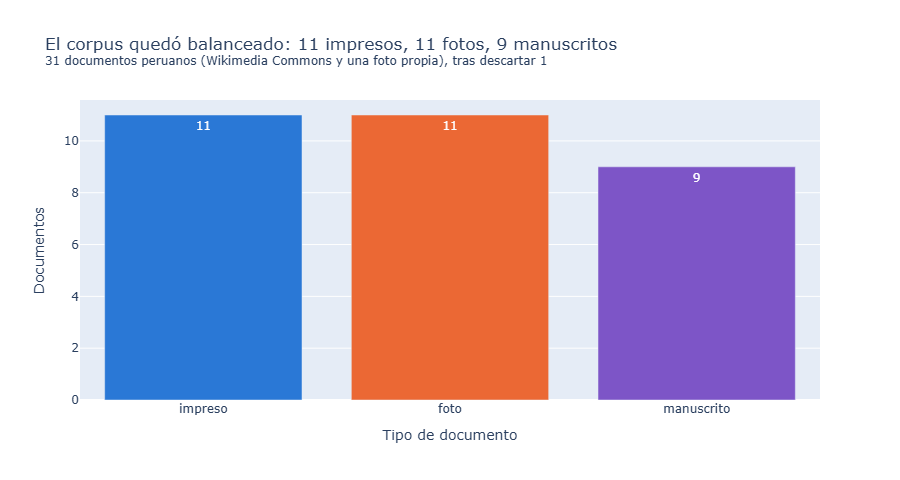

In [18]:
publicar_docs = docs_ok.assign(texto=docs_ok["texto_ocr_publicable"])
publicar_auds = auds_ok.assign(texto=auds_ok["texto_asr_publicable"])
publicar_docs["n_caracteres"] = publicar_docs["texto"].str.len()
publicar_auds["n_palabras"] = publicar_auds["texto"].str.replace(r"\[HABLANTE_\d+\]", "", regex=True).str.split().str.len()

COLORES = {"impreso": "#2a78d6", "foto": "#eb6834", "manuscrito": "#7d55c7",
           "testimonio": "#1f9e89", "entrevista": "#e3a21a", "fiesta": "#d03b6b", "calle": "#6b7a8f", "conferencia": "#8fb339"}
conteo = publicar_docs["tipo"].value_counts().reindex(["impreso", "foto", "manuscrito"]).reset_index()
fig = px.bar(conteo, x="tipo", y="count", text="count", color="tipo", color_discrete_map=COLORES,
             labels={"tipo": "Tipo de documento", "count": "Documentos"},
             title=f"El corpus quedó balanceado: {', '.join(f'{n} {t}s' for t, n in zip(conteo['tipo'], conteo['count']))}"
                   f"<br><sup>{len(publicar_docs)} documentos peruanos (Wikimedia Commons y una foto propia), tras descartar {len(docs) - len(docs_ok)}</sup>")
fig.update_layout(showlegend=False, width=900, height=480)
fig.show()

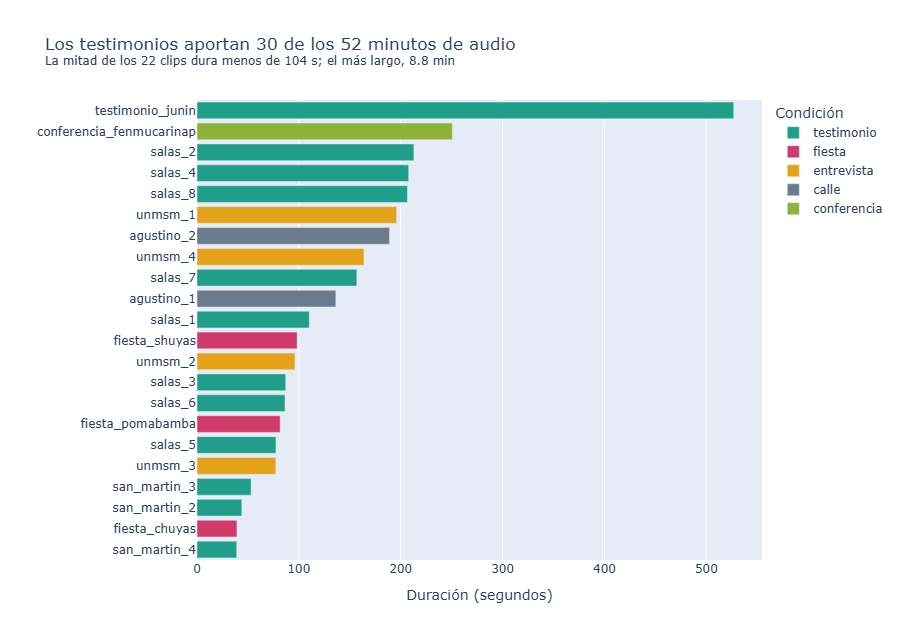

In [19]:
minutos = publicar_auds.groupby("condicion")["duracion_seg"].sum().div(60)
fig = px.bar(publicar_auds.sort_values("duracion_seg"), x="duracion_seg", y="clave", color="condicion", orientation="h",
             color_discrete_map=COLORES,
             labels={"duracion_seg": "Duración (segundos)", "clave": "", "condicion": "Condición"},
             title=f"Los testimonios aportan {minutos['testimonio']:.0f} de los {minutos.sum():.0f} minutos de audio"
                   f"<br><sup>La mitad de los {len(publicar_auds)} clips dura menos de "
                   f"{publicar_auds['duracion_seg'].median():.0f} s; el más largo, {publicar_auds['duracion_seg'].max() / 60:.1f} min</sup>")
fig.update_layout(width=900, height=640, yaxis={"categoryorder": "total ascending"})
fig.show()

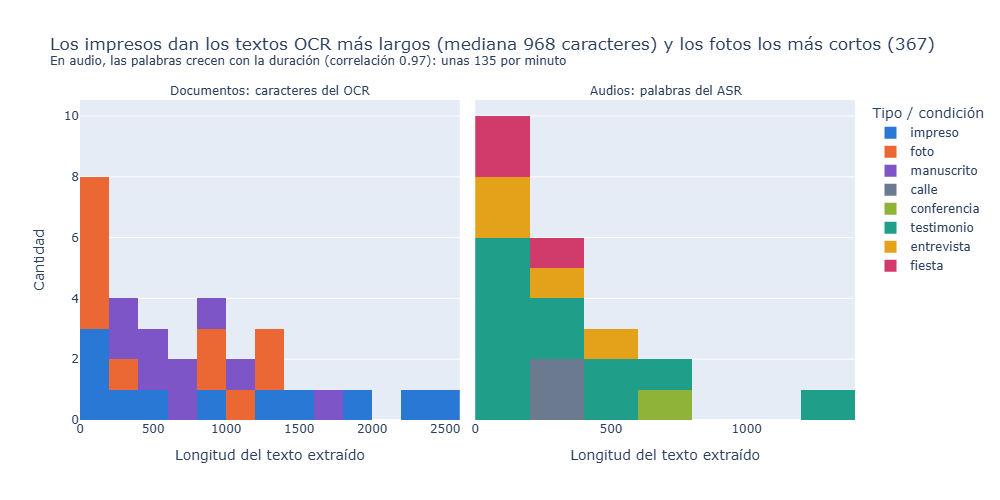

In [20]:
longitudes = pd.concat([
    pd.DataFrame({"modalidad": "Documentos: caracteres del OCR", "longitud": publicar_docs["n_caracteres"], "tipo": publicar_docs["tipo"]}),
    pd.DataFrame({"modalidad": "Audios: palabras del ASR", "longitud": publicar_auds["n_palabras"], "tipo": publicar_auds["condicion"]}),
])
medianas = publicar_docs.groupby("tipo")["n_caracteres"].median().sort_values()
correlacion = publicar_auds[["duracion_seg", "n_palabras"]].corr().iloc[0, 1]
fig = px.histogram(longitudes, x="longitud", color="tipo", facet_col="modalidad", nbins=15, color_discrete_map=COLORES,
                   labels={"longitud": "Longitud del texto extraído", "tipo": "Tipo / condición"},
                   title=f"Los {medianas.index[-1]}s dan los textos OCR más largos (mediana {medianas.iloc[-1]:.0f} caracteres) "
                         f"y los {medianas.index[0]}s los más cortos ({medianas.iloc[0]:.0f})"
                         f"<br><sup>En audio, las palabras crecen con la duración (correlación {correlacion:.2f}): "
                         f"unas {publicar_auds['n_palabras'].sum() / (publicar_auds['duracion_seg'].sum() / 60):.0f} por minuto</sup>")
fig.update_xaxes(matches=None)
fig.update_yaxes(title_text="Cantidad", col=1)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_layout(width=1000, height=500)
fig.show()

## 8 · Validación: extremos de cada histograma

In [21]:
columnas = ["id", "clave", "tipo", "n_caracteres", "conf_mediana"]
print("Documentos con el OCR más largo:")
display(publicar_docs.nlargest(3, "n_caracteres")[columnas])
print("Documentos con el OCR más corto:")
display(publicar_docs.nsmallest(3, "n_caracteres")[columnas + ["texto"]])

Documentos con el OCR más largo:


,id,clave,tipo,n_caracteres,conf_mediana
1,doc_002,guerra_marina_1823,impreso,2545,0.988
0,doc_001,mache_acta_simbolos,impreso,2333,0.993
2,doc_003,riva_aguero_1823,impreso,1848,0.994


Documentos con el OCR más corto:


,id,clave,tipo,n_caracteres,conf_mediana,texto
15,doc_016,letrero_calle_20,foto,11,0.9395,CALE\nBEYTIA
14,doc_015,letrero_herrador,foto,16,0.9710,ANCO\nEL\nHEDRADOR
17,doc_018,placa_nazarenas,foto,70,1.0000,2DOMINO\nPRO\nさ八十十+メ\nCITUUM\nMONASTERIO DE NAZARENAS\nCARMELITAS\nDESCALZAS


In [22]:
columnas = ["id", "clave", "condicion", "duracion_seg", "n_palabras", "n_hablantes"]
print("Clips más largos:")
display(publicar_auds.nlargest(3, "duracion_seg")[columnas])
print("Clips más cortos:")
display(publicar_auds.nsmallest(3, "duracion_seg")[columnas + ["texto"]])
palabras_por_minuto = publicar_auds["n_palabras"].sum() / (publicar_auds["duracion_seg"].sum() / 60)
print(f"Ritmo medio: {palabras_por_minuto:.0f} palabras por minuto de audio")

Clips más largos:


,id,clave,condicion,duracion_seg,n_palabras,n_hablantes
3,clip_004,testimonio_junin,testimonio,526.9,1229,2
2,clip_003,conferencia_fenmucarinap,conferencia,250.6,633,3
5,clip_006,salas_2,testimonio,212.9,672,1


Clips más cortos:


,id,clave,condicion,duracion_seg,n_palabras,n_hablantes,texto
18,clip_019,san_martin_4,testimonio,39.0,74,1,Creo que ser una mujer dedicada al agro es algo que hoy en día han cambiado mucho porque con todas las cap...
21,clip_022,fiesta_chuyas,fiesta,39.2,75,1,"Buenos días, joven. Claro que sí, la fiesta de Santo Patrón de Chuya, Taitapalli, es muy importante para m..."
16,clip_017,san_martin_2,testimonio,44.0,96,1,"Yo creo que el tema de identificar las brechas relacionadas a la mujer campesina es algo muy visible, porq..."


Ritmo medio: 135 palabras por minuto de audio


## 9 · Exportación

In [23]:
documentos = pd.DataFrame({
    "id": publicar_docs["id"],
    "archivo": publicar_docs["archivo"].str.replace("\\", "/", regex=False),
    "tipo": publicar_docs["tipo"],
    "fuente": publicar_docs["origen"] + " (" + publicar_docs["licencia"] + ") · " + publicar_docs["autor"],
    "texto_ocr": publicar_docs["texto"],
    "modelo_ocr": MODELO_OCR,
    "texto_referencia": "",
    "titulo": publicar_docs["titulo"],
    "n_caracteres": publicar_docs["n_caracteres"],
    "n_lineas": publicar_docs["n_lineas"],
    "conf_mediana": publicar_docs["conf_mediana"].round(3),
    "url_imagen": publicar_docs["url_descarga"],
    # la imagen se muestra solo si es de Commons y su texto no tenía datos personales
    "imagen_publicable": (publicar_docs["origen"] == "Wikimedia Commons") & ~publicar_docs["id"].isin(cambios["id"]),
})
transcripciones = pd.DataFrame({
    "id": publicar_auds["id"],
    "archivo_audio": publicar_auds["archivo_audio"].str.replace("\\", "/", regex=False),
    "duracion_seg": publicar_auds["duracion_seg"],
    "idioma": "es (fijado; español peruano según la fuente)",
    "texto_asr": publicar_auds["texto"],
    "modelo_asr": NOMBRE_ASR,
    "n_hablantes": publicar_auds["n_hablantes"],
    "texto_referencia": "",
    "titulo": publicar_auds["titulo"],
    "condicion": publicar_auds["condicion"],
    "fuente": "Wikimedia Commons (" + publicar_auds["licencia"] + ") · " + publicar_auds["autor"],
    "n_palabras": publicar_auds["n_palabras"],
    "pct_voz": publicar_auds["pct_voz"],
    "segundos_asr": publicar_auds["id"].map(tiempos).round(1),
    "url_audio": publicar_auds["url_descarga"],
})

estado = descartes.set_index("id")["motivo"]
fuentes = pd.concat([
    pd.DataFrame({"id": docs["id"], "modalidad": "documento", "clave": docs["clave"], "fuente_url": docs["fuente_url"],
                  "licencia": docs["licencia"], "autor": docs["autor"], "archivo_commons": docs["archivo_commons"],
                  "acceso": [f"descarga directa: {u}" if u else "foto propia tomada el 24-10-2026; la imagen no se publica"
                             for u in docs["url_descarga"]]}),
    pd.DataFrame({"id": auds["id"], "modalidad": "audio", "clave": auds["clave"], "fuente_url": auds["fuente_url"],
                  "licencia": auds["licencia"], "autor": auds["autor"], "archivo_commons": auds["archivo_commons"],
                  "acceso": "descarga directa: " + auds["url_descarga"]}),
])
fuentes["fecha_extraccion"] = FECHA_EXTRACCION
fuentes["estado"] = fuentes["id"].map(lambda i: "descartado: " + estado[i] if i in estado.index else "incluido")
fuentes.loc[fuentes["acceso"].str.startswith("descarga"), "acceso"] += " (o ejecutar la sección 2 de 01_extraccion.ipynb)"

documentos.to_csv(DATOS / "documentos.csv", index=False, encoding="utf-8")
transcripciones.to_csv(DATOS / "transcripciones.csv", index=False, encoding="utf-8")
fuentes.to_csv(DATOS / "fuentes.csv", index=False, encoding="utf-8")
cambios.to_csv(DATOS / "seudonimizacion.csv", index=False, encoding="utf-8")

# textos sin seudonimizar: solo para medir CER y WER en la Parte 2 (datos/raw/ no se sube a GitHub)
docs_ok[["id", "clave", "tipo", "texto_ocr"]].to_csv(DATOS / "raw" / "ocr_crudo.csv", index=False, encoding="utf-8")
auds_ok[["id", "clave", "condicion", "texto_asr_crudo"]].to_csv(DATOS / "raw" / "asr_crudo.csv", index=False, encoding="utf-8")

for nombre, tabla in [("documentos", documentos), ("transcripciones", transcripciones), ("fuentes", fuentes)]:
    print(f"datos/{nombre}.csv: {tabla.shape}")

datos/documentos.csv: (31, 13)
datos/transcripciones.csv: (22, 15)
datos/fuentes.csv: (56, 10)


In [24]:
documentos.head()

,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia,titulo,n_caracteres,n_lineas,conf_mediana,url_imagen,imagen_publicable
0,doc_001,datos/raw/documentos/originales/doc_001.jpg,impreso,Wikimedia Commons (CC BY 4.0) · Helder Zavaleta Verde,"ACTA DE OFICIALIZACIÓN DE LOS SÍMBOLOS PARA EL DISTRITO DE\nMACME.\nCONSIDERANDO:\nQue, de conformidad a l...",PaddleOCR 3.7.0 · PP-OCRv6_medium (det + rec) · motor PyTorch en CPU · sin orientación ni enderezado · ima...,,Acta de oficialización de los símbolos de Mache (La Libertad),2333,38,0.993,https://upload.wikimedia.org/wikipedia/commons/0/04/Acta_de_Creaci%C3%B3n_de_los_S%C3%ADmbolos_para_el_Dis...,False
1,doc_002,datos/raw/documentos/originales/doc_002.jpg,impreso,Wikimedia Commons (CC BY-SA 4.0) · Jrodriguez1901,Ministerio de la Guerra\ny Marina\nLima. Septiembre 14 de 1823.\nSeñor Ministro de Estado en el Departamen...,PaddleOCR 3.7.0 · PP-OCRv6_medium (det + rec) · motor PyTorch en CPU · sin orientación ni enderezado · ima...,,"Oficio del Ministerio de la Guerra y Marina, 1823 (edición impresa)",2545,47,0.988,https://upload.wikimedia.org/wikipedia/commons/4/4c/Ministerio_de_la_Guerra_y_Marina-.jpg,True
2,doc_003,datos/raw/documentos/originales/doc_003.jpg,impreso,Wikimedia Commons (CC BY-SA 4.0) · Jrodriguez1901,"Trujillo, 25 de Julio de 1823.\nExcmo. Señer General don Ramón Freire.\nMi distinguido amigo y señor:\nLos...",PaddleOCR 3.7.0 · PP-OCRv6_medium (det + rec) · motor PyTorch en CPU · sin orientación ni enderezado · ima...,,"Carta de José de la Riva-Agüero a Ramón Freire, 1823 (edición impresa)",1848,33,0.994,https://upload.wikimedia.org/wikipedia/commons/e/ee/1%C2%BA_Presidente_de_Peru-_Jos%C3%A9_de_la_Riva_Ag%C3...,False
3,doc_004,datos/raw/documentos/originales/doc_004.jpg,impreso,Wikimedia Commons (Dominio público) · Vlanco24,"HIMNO DE CHANCHAMAYO\nCORO\nChanchamayo, el “PERÚ” te Proclama\nCorazón de la ""Selva Central""\nEste canto ...",PaddleOCR 3.7.0 · PP-OCRv6_medium (det + rec) · motor PyTorch en CPU · sin orientación ni enderezado · ima...,,Afiche con la letra del Himno de Chanchamayo,1235,47,0.999,https://upload.wikimedia.org/wikipedia/commons/b/ba/Himno_Chyo.jpg,False
4,doc_005,datos/raw/documentos/originales/doc_005.jpg,impreso,"Wikimedia Commons (Dominio público) · El Cascabel (revista, Lima)","ALMANAQUE\n1DE\n""EL CASCABEL""\nPARA EL AÑO 1873,\nCan an sluvion de casas divertidas, humoristicas. estupe...",PaddleOCR 3.7.0 · PP-OCRv6_medium (det + rec) · motor PyTorch en CPU · sin orientación ni enderezado · ima...,,"Portada del Almanaque de El Cascabel, Lima, 1873",276,15,0.838,https://upload.wikimedia.org/wikipedia/commons/thumb/9/9a/Almanaque_de_El_Cascabel_para_el_a%C3%B1o_1873_%...,True


In [25]:
transcripciones.head()

,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia,titulo,condicion,fuente,n_palabras,pct_voz,segundos_asr,url_audio
0,clip_001,datos/raw/audio/wav/clip_001.wav,136.3,es (fijado; español peruano según la fuente),"[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme su opinión acerca de ...","faster-whisper 1.2.1 small (int8, CPU, VAD on, beam 5, es)",2,,"Vendedora de frutas entrevistada en la calle, El Agustino (Lima), 2022",calle,Wikimedia Commons (CC BY-SA 4.0) · JorgeFlores-pe (Wikimedia Perú),258,0.774,23.3,https://upload.wikimedia.org/wikipedia/commons/0/0d/Entrevista_1_en_la_Av._Rivag%C3%BCero_-_El_Agustino.ogg
1,clip_002,datos/raw/audio/wav/clip_002.wav,189.0,es (fijado; español peruano según la fuente),[HABLANTE_1] Buenos días profesor y compañeros. Hoy estoy cerca de aquí por mi casa y voy a hacer entrevis...,"faster-whisper 1.2.1 small (int8, CPU, VAD on, beam 5, es)",5,,"Dos vendedoras de dulces y el entrevistador, El Agustino (Lima), 2022",calle,Wikimedia Commons (CC BY-SA 4.0) · JorgeFlores-pe (Wikimedia Perú),352,0.829,36.1,https://upload.wikimedia.org/wikipedia/commons/d/df/Entrevista_2_en_la_Av._Rivag%C3%BCero_-_El_Agustino.ogg
2,clip_003,datos/raw/audio/wav/clip_003.wav,250.6,es (fijado; español peruano según la fuente),"[HABLANTE_1] Bueno, hola, estamos en los San Martín, entre Fritas Patreas, 28 de julio. Entonces, primero ...","faster-whisper 1.2.1 small (int8, CPU, VAD on, beam 5, es)",3,,"Dirigente de Fenmucarinap durante una conferencia de prensa, 2022",conferencia,Wikimedia Commons (CC BY-SA 4.0) · QM Keen,633,0.956,58.6,https://upload.wikimedia.org/wikipedia/commons/3/3e/Entrevista-Aurora_Coronado-organizaci%C3%B3n_de_mujere...
3,clip_004,datos/raw/audio/wav/clip_004.wav,526.9,es (fijado; español peruano según la fuente),[HABLANTE_1] mi nombre es [PERSONA_29].\n[HABLANTE_2] ¿De dónde vienes? ¿Cuál es tu comunidad?\n[HABLANTE_...,"faster-whisper 1.2.1 small (int8, CPU, VAD on, beam 5, es)",2,,"Lideresa campesina de Junín, testimonio, 2024",testimonio,Wikimedia Commons (CC BY-SA 4.0) · Eiciwiki,1229,0.972,148.8,https://upload.wikimedia.org/wikipedia/commons/9/97/Testimonio_Lucinda_Quispealaya_-_Jun%C3%ADn.ogg
4,clip_005,datos/raw/audio/wav/clip_005.wav,110.2,es (fijado; español peruano según la fuente),"Yo casi iba mucho al cine de calle, claro, pero generalmente por donde yo vivía, no sé, miro flores, y tam...","faster-whisper 1.2.1 small (int8, CPU, VAD on, beam 5, es)",1,,"Testimonio sobre salas de cine (WikiAcción Perú), 2026",testimonio,Wikimedia Commons (CC BY 4.0) · Renzo Rojas Alvarez,228,0.890,23.5,https://upload.wikimedia.org/wikipedia/commons/2/29/Testimonio_1_-_Salas%2C_pantallas_y_archivos_01.ogg


In [26]:
fuentes.head()

,id,modalidad,clave,fuente_url,licencia,autor,archivo_commons,acceso,fecha_extraccion,estado
0,doc_001,documento,mache_acta_simbolos,https://commons.wikimedia.org/wiki/File:Acta_de_Creaci%C3%B3n_de_los_S%C3%ADmbolos_para_el_Distrito_de_Mac...,CC BY 4.0,Helder Zavaleta Verde,Acta de Creación de los Símbolos para el Distrito de Mache - Perù.jpg,descarga directa: https://upload.wikimedia.org/wikipedia/commons/0/04/Acta_de_Creaci%C3%B3n_de_los_S%C3%AD...,2026-10-24,incluido
1,doc_002,documento,guerra_marina_1823,https://commons.wikimedia.org/wiki/File:Ministerio_de_la_Guerra_y_Marina-.jpg,CC BY-SA 4.0,Jrodriguez1901,Ministerio de la Guerra y Marina-.jpg,descarga directa: https://upload.wikimedia.org/wikipedia/commons/4/4c/Ministerio_de_la_Guerra_y_Marina-.jp...,2026-10-24,incluido
2,doc_003,documento,riva_aguero_1823,https://commons.wikimedia.org/wiki/File:1%C2%BA_Presidente_de_Peru-_Jos%C3%A9_de_la_Riva_Ag%C3%BCero.jpg,CC BY-SA 4.0,Jrodriguez1901,1º Presidente de Peru- José de la Riva Agüero.jpg,descarga directa: https://upload.wikimedia.org/wikipedia/commons/e/ee/1%C2%BA_Presidente_de_Peru-_Jos%C3%A...,2026-10-24,incluido
3,doc_004,documento,himno_chanchamayo,https://commons.wikimedia.org/wiki/File:Himno_Chyo.jpg,Dominio público,Vlanco24,Himno Chyo.jpg,descarga directa: https://upload.wikimedia.org/wikipedia/commons/b/ba/Himno_Chyo.jpg (o ejecutar la secció...,2026-10-24,incluido
4,doc_005,documento,almanaque_cascabel_1873,https://commons.wikimedia.org/wiki/File:Almanaque_de_El_Cascabel_para_el_a%C3%B1o_1873_%281000062591-0003%...,Dominio público,"El Cascabel (revista, Lima)",Almanaque de El Cascabel para el año 1873 (1000062591-0003).pdf,descarga directa: https://upload.wikimedia.org/wikipedia/commons/thumb/9/9a/Almanaque_de_El_Cascabel_para_...,2026-10-24,incluido


**Ejemplos para el dashboard.** Se publican los primeros 30 s de los clips en los que no se dijo ningún nombre de
persona ni dato de contacto (según la sección 6), en OGG mono de 16 kHz. Todos tienen licencia CC BY o CC BY-SA,
que permite redistribuirlos citando la fuente (la atribución está en `datos/fuentes.csv` y en el dashboard).

In [27]:
EJEMPLOS = DATOS / "ejemplos"
EJEMPLOS.mkdir(exist_ok=True)
sin_datos = auds_ok[~auds_ok["id"].isin(cambios["id"])]
for fila in sin_datos.itertuples():
    audio = voz.cargar_audio(fila.archivo_audio)[: 30 * voz.SR]
    sf.write(EJEMPLOS / f"{fila.id}.ogg", audio, voz.SR, format="OGG", subtype="VORBIS")
kb = sum(p.stat().st_size for p in EJEMPLOS.glob("*.ogg")) / 1e3
print(f"{len(sin_datos)} fragmentos de 30 s en datos/ejemplos/ ({kb:.0f} KB en total)")

12 fragmentos de 30 s en datos/ejemplos/ (1753 KB en total)


## 10 · Resumen

- **Corpus.** De 32 documentos candidatos quedaron **31**: 11 impresos o mecanografiados, 11 fotos (10 de Commons y
  una propia) y 9 manuscritos. Se descartó la carta del Banco Internacional de 1927 porque su texto está tan desvaído que no se lee
  ni a simple vista. De 24 audios quedaron **22 clips con 52,3 minutos**. El himno de la Marina y el silbador se
  descartaron porque el VAD no encontró voz (0 %): el canto con banda no se reconoce como voz hablada. No hubo
  duplicados exactos (MD5) ni visuales (dHash).
- **OCR.** PaddleOCR tardó unos 30 s por documento en la CPU de la laptop (16 min en total). La confianza mediana es
  0,99 en impresos y fotos, pero 0,74 en manuscritos, que además tienen 21 líneas dudosas por documento frente a
  1 o 2 en los otros tipos. En las fotos el problema son las palabras pegadas («EDIFICIOFENIX») y las letras perdidas
  en letreros cortos («ANCO EL HEDRADOR» por «Banco del Herrador»).
- **ASR.** faster-whisper `small` transcribió 52,3 min en 12,5 min (factor de tiempo real 0,24). En la fiesta de
  Shuyas el VAD solo encontró 10,6 s de voz en 98 s por la banda de música, así que la transcripción tiene apenas
  dos frases. 12 de los 22 clips tienen más de un hablante; la diarización exagera en la calle: la entrevista
  `agustino_2` sale con 5 hablantes y se oyen 3.
- **Seudonimización.** El NER marcó 67 textos como nombres de persona: 18 eran cargos, títulos o ruido del OCR, 13
  eran personajes públicos o históricos y 36 se seudonimizaron. En la revisión humana se agregaron 2 nombres que el
  NER no reconoció (uno mal escrito por el ASR y otro en el borde de la foto propia). En total se reemplazaron
  **49 entidades** (48 nombres y 1 dirección) en 22 textos.